# Разведывательный анализ данных

### Назначение: 
Разведывательный анализ данных (EDA).
### Содержимое:
- Визуализации ЭЭГ-сигналов (покой, таблицы Шульте).
- Первичная статистика: длительность записей, частота дискретизации, пропуски, артефакты.
- Анализ распределений по группам (норма, ПТСР, соматоформные).
- Выявление аномалий и выбросов.
- Первичные гипотезы о признаках, связанных с ПТСР.
- Анализ доступных конфаундеров: возраст (где известен), пол, поведенческие показатели.

**Важная особенность аппаратуры, которую нужно держать в голове на каждом
шаге ниже: референсный электрод расположен на левом ухе.** Это значит, что
левополушарные каналы (Fp1, T3, O1) физически ближе к референсу, чем
правополушарные (Fp2, T4, O2) — асимметрия амплитуды между полушариями
может быть частично или полностью артефактом схемы отведения, а не
реальной физиологией. Ниже это проверяется отдельно (раздел 6), **до**
того, как делать какие-либо выводы про фронтальную/височную асимметрию.

### Импорты и конфигурация

In [1]:
import re
import random
import warnings
from pathlib import Path
from collections import defaultdict
 
import numpy as np
import pandas as pd
from scipy import signal, stats as sps
 
import mne
 
import matplotlib.pyplot as plt
import seaborn as sns

import unicodedata
from collections import Counter
 
warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
sns.set_theme(style="whitegrid")
 
%matplotlib inline

In [2]:
DATA_DIR = Path("/home/veronika/neurotone/atacheskaya-panika/data/neurodiagnostics-train")  # подставьте свой путь
 
CHANNELS = ["Fp1", "Fp2", "T3", "T4", "O1", "O2"]
LEFT_CH = ["Fp1", "T3", "O1"]
RIGHT_CH = ["Fp2", "T4", "O2"]
 
GROUPS = ["Норма", "ПТСР", "Соматоформные"]  # поправьте под реальные имена папок, если отличаются
 
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

In [3]:
def classify_file(stem: str) -> str:
    s = unicodedata.normalize("NFKC", stem).strip().upper()
    s = s.replace("–", "-").replace("—", "-").replace("−", "-")

    m = re.fullmatch(r"T[\s\-_]*([1-5])", s)
    if m:
        return f"task_{m.group(1)}"
    m = re.fullmatch(r"T[\s\-_]*([ПP])", s)
    if m:
        return "rest"   # было "task_simple"
    return "unknown"
 
 
# def get_age(group_name: str, subj_name: str):
#     """Возраст закодирован в имени папки только для группы 'Норма' (п. 3.1 ТЗ)."""
#     if not group_name.lower().startswith("норм"):
#         return None
#     m = re.search(r"_(\\d+)$", subj_name)
#     return int(m.group(1)) if m else None

def get_age(group_name: str, subj_name: str):
    if not group_name.lower().startswith("норм"):
        return None
    m = re.search(r"_(\d+)$", subj_name)   # один \, не два
    return int(m.group(1)) if m else None

### Инвентаризация данных

Сколько испытуемых в каждой группе, у всех ли по 6 файлов (покой + 5 таблиц),
нет ли пустых/битых папок.

In [4]:
inventory_rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        files = sorted(subj_dir.glob("*.edf"))
        kinds = [classify_file(f.stem) for f in files]
        inventory_rows.append(dict(
            group=group_dir.name,
            subject=subj_dir.name,
            age=get_age(group_dir.name, subj_dir.name),
            n_files=len(files),
            has_rest=("rest" in kinds),
            n_tasks=sum(k.startswith("task") for k in kinds),
            unknown_files=[f.name for f, k in zip(files, kinds) if k == "unknown"],
        ))
 
inv_df = pd.DataFrame(inventory_rows)
print("Всего испытуемых:", len(inv_df))
print(inv_df.groupby("group").size())

Всего испытуемых: 166
group
Норма            67
ПТСР             25
Соматоформные    74
dtype: int64


In [5]:
print("Распределение количества файлов на испытуемого (ожидается 6):")
print(inv_df["n_files"].value_counts().sort_index())
 
print("\\nИспытуемые без записи покоя:")
print(inv_df.loc[~inv_df["has_rest"], ["group", "subject", "n_files"]])
 
print("\\nИспытуемые с нестандартным числом таблиц (ожидается 5):")
print(inv_df.loc[inv_df["n_tasks"] != 5, ["group", "subject", "n_tasks"]])
 
unknown_all = inv_df.loc[inv_df["unknown_files"].map(len) > 0, ["group", "subject", "unknown_files"]]
print("\\nФайлы, не распознанные classify_file (нужно поправить regex или это мусорные файлы):")
print(unknown_all)

Распределение количества файлов на испытуемого (ожидается 6):
n_files
6    166
Name: count, dtype: int64
\nИспытуемые без записи покоя:
Empty DataFrame
Columns: [group, subject, n_files]
Index: []
\nИспытуемые с нестандартным числом таблиц (ожидается 5):
Empty DataFrame
Columns: [group, subject, n_tasks]
Index: []
\nФайлы, не распознанные classify_file (нужно поправить regex или это мусорные файлы):
Empty DataFrame
Columns: [group, subject, unknown_files]
Index: []


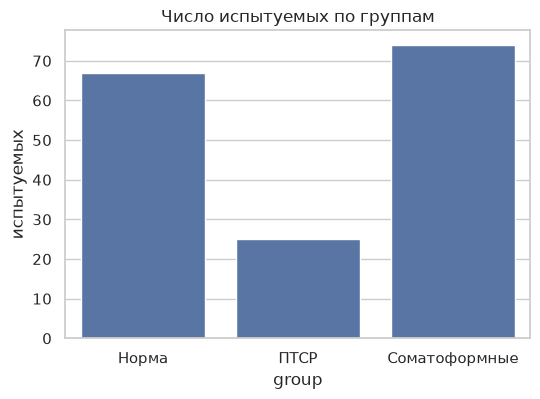

In [6]:
plt.figure(figsize=(6, 4))
sns.countplot(data=inv_df, x="group", order=GROUPS)
plt.title("Число испытуемых по группам")
plt.ylabel("испытуемых")
plt.show()

### Первичная статистика записей

Длительность, частота дискретизации, единицы измерения — то, что ТЗ прямо
просит не считать константой (п. 3.2): 125 vs 126 Гц, неоднородное
масштабирование в заголовке EDF.

In [7]:
def read_file_meta(path):
    raw = mne.io.read_raw_edf(path, preload=False, verbose=False)
    return dict(
        sfreq=int(round(raw.info["sfreq"])),
        n_channels=len(raw.ch_names),
        ch_names=tuple(raw.ch_names),
        duration_s=raw.n_times / raw.info["sfreq"],
    )
 
 
meta_rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        for f in sorted(subj_dir.glob("*.edf")):
            try:
                meta = read_file_meta(f)
                meta_rows.append(dict(
                    group=group_dir.name, subject=subj_dir.name, file=f.name,
                    kind=classify_file(f.stem), **meta,
                ))
            except Exception as e:
                meta_rows.append(dict(
                    group=group_dir.name, subject=subj_dir.name, file=f.name,
                    kind=classify_file(f.stem), error=str(e),
                ))
 
meta_df = pd.DataFrame(meta_rows)
print("Файлов с ошибкой чтения:", meta_df.get("error", pd.Series(dtype=object)).notna().sum())
meta_df.head()

Файлов с ошибкой чтения: 5


,group,subject,file,kind,sfreq,n_channels,ch_names,duration_s,error
0,Норма,КС010_19,T-1.edf,task_1,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",63.0,NaN
1,Норма,КС010_19,T-2.edf,task_2,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",44.0,NaN
2,Норма,КС010_19,T-3.edf,task_3,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",50.0,NaN
3,Норма,КС010_19,T-4.edf,task_4,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",33.0,NaN
4,Норма,КС010_19,T-5.edf,task_5,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",50.0,NaN


In [8]:
print("Уникальные частоты дискретизации в наборе:")
print(meta_df["sfreq"].value_counts())
 
print("\nУникальные наборы имён каналов (порядок может отличаться между файлами — п. 3.2 ТЗ):")
print(meta_df["ch_names"].value_counts())
 
print("\nЧастота дискретизации по группам — проверка, что распределение sfreq не совпадает с меткой класса")
print(pd.crosstab(meta_df["group"], meta_df["sfreq"]))

Уникальные частоты дискретизации в наборе:
sfreq
125.0    783
126.0     58
124.0     52
127.0     51
123.0     47
Name: count, dtype: int64

Уникальные наборы имён каналов (порядок может отличаться между файлами — п. 3.2 ТЗ):
ch_names
(O1, T3, Fp1, Fp2, T4, O2)    991
Name: count, dtype: int64

Частота дискретизации по группам — проверка, что распределение sfreq не совпадает с меткой класса
sfreq          123.0  124.0  125.0  126.0  127.0
group                                           
Норма             47     52    194     58     51
ПТСР               0      0    150      0      0
Соматоформные      0      0    439      0      0


In [9]:
meta_df[meta_df["sfreq"] != 125.0] \
    .groupby(["group","subject"])["sfreq"] \
    .agg(["count","nunique","unique"])

count  nunique                        unique
group         subject                                               
Норма         КС056_22      4        3         [126.0, 127.0, 123.0]
              КС058_24      6        3         [127.0, 124.0, 123.0]
              КС059_35      6        3         [126.0, 123.0, 124.0]
              КС060_26      4        4  [123.0, 126.0, 124.0, 127.0]
              КС063_25      5        4  [127.0, 123.0, 126.0, 124.0]
              КС064_58      5        4  [123.0, 126.0, 124.0, 127.0]
              КС066_45      5        4  [123.0, 127.0, 124.0, 126.0]
              КС067_28      4        4  [124.0, 127.0, 123.0, 126.0]
              КС071_39      4        3         [126.0, 124.0, 127.0]
              КС074_33      5        2                [123.0, 127.0]
              КС076_28      4        4  [124.0, 123.0, 127.0, 126.0]
              КС077_26      4        3         [127.0, 123.0, 124.0]
              КС079_31      5        2                [124.0, 126.0]
              КС080_22      4        3         [123.0, 124.0, 126.0]
              КС081_37      6        3         [126.0, 124.0, 127.0]
              КС082_34      5        2                [126.0, 124.0]
              КС086_29      4        3         [126.0, 124.0, 123.0]
              КС088_52      6        3         [124.0, 126.0, 123.0]
              КС090_45      2        2                [123.0, 124.0]
              КС092_27      5        3         [124.0, 126.0, 127.0]
              КС094_33      5        3         [126.0, 124.0, 127.0]
              КС096_31      6        4  [124.0, 127.0, 126.0, 123.0]
              КС098_49      4        3         [123.0, 127.0, 126.0]
              КС100_22      6        3         [123.0, 124.0, 127.0]
              КС102_36      4        3         [127.0, 123.0, 126.0]
              КС104_28      3        2                [127.0, 124.0]
              КС106_51      5        2                [127.0, 123.0]
              КС108_25      4        3         [127.0, 126.0, 123.0]
              КС110_32      5        3         [126.0, 123.0, 124.0]
              КС112_54      3        2                [127.0, 123.0]
              КС116_46      4        2                [124.0, 127.0]
              КС118_58      5        3         [127.0, 123.0, 126.0]
              КС120_21      6        4  [126.0, 123.0, 124.0, 127.0]
              КС122_34      4        4  [127.0, 124.0, 123.0, 126.0]
              КС124_48      6        4  [124.0, 126.0, 127.0, 123.0]
              КС126_41      6        3         [124.0, 127.0, 123.0]
              КС128_55      3        2                [123.0, 126.0]
              КС130_44      4        3         [127.0, 126.0, 124.0]
              КС132_57      4        3         [124.0, 126.0, 127.0]
              КС134_23      4        3         [126.0, 124.0, 123.0]
              КС136_32      5        2                [126.0, 124.0]
              КС138_52      5        4  [127.0, 124.0, 123.0, 126.0]
              КС140_20      5        3         [124.0, 126.0, 123.0]
              КС142_39      5        4  [126.0, 123.0, 124.0, 127.0]
              КС144_46      4        3         [127.0, 123.0, 126.0]
Соматоформные XCFU5         0        0                         [nan]

In [10]:
import pyedflib
from pathlib import Path

# найдём файлы субъекта, у которого sfreq скачет
candidates = list(DATA_DIR.rglob("КС060_26/*.edf"))[:3]
print(candidates)

for p in candidates:
    f = pyedflib.EdfReader(str(p))
    print(f"\n=== {p.name} ===")
    for i, ch in enumerate(f.getSignalLabels()):
        print(f"  {ch:>10s}  sfreq={f.getSampleFrequency(i)}  n={f.getNSamples()[i]}")
    f.close()

[PosixPath('/home/veronika/neurotone/atacheskaya-panika/data/neurodiagnostics-train/Норма/КС060_26/T-2.edf'), PosixPath('/home/veronika/neurotone/atacheskaya-panika/data/neurodiagnostics-train/Норма/КС060_26/T-4.edf'), PosixPath('/home/veronika/neurotone/atacheskaya-panika/data/neurodiagnostics-train/Норма/КС060_26/T-П.edf')]

=== T-2.edf ===
          O1  sfreq=125.0  n=6625
          T3  sfreq=125.0  n=6625
         Fp1  sfreq=125.0  n=6625
         Fp2  sfreq=125.0  n=6625
          T4  sfreq=125.0  n=6625
          O2  sfreq=125.0  n=6625

=== T-4.edf ===
          O1  sfreq=126.0  n=6678
          T3  sfreq=126.0  n=6678
         Fp1  sfreq=126.0  n=6678
         Fp2  sfreq=126.0  n=6678
          T4  sfreq=126.0  n=6678
          O2  sfreq=126.0  n=6678

=== T-П.edf ===
          O1  sfreq=127.0  n=7747
          T3  sfreq=127.0  n=7747
         Fp1  sfreq=127.0  n=7747
         Fp2  sfreq=127.0  n=7747
          T4  sfreq=127.0  n=7747
          O2  sfreq=127.0  n=7747


In [11]:
meta_df.groupby("group")["duration_s"].describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Норма,402.0,47.042289,12.184807,17.0,36.25,46.5,53.00,133.0
ПТСР,150.0,60.873333,22.209889,8.0,46.00,59.0,69.75,123.0
Соматоформные,439.0,48.952164,16.962085,1.0,37.00,46.0,60.00,142.0


Разброс огромный во всех трёх группах — от 1 с до 142 с.

У Нормы — самый узкий разброс (std 12.2) и нет «длинных» записей >133 с.

У ПТСР — самый широкий разброс (std 22.2), средняя длительность заметно выше (61 с vs 47/49).

Есть файлы длительностью 1 с (Соматоформные) и 8 с (ПТСР) — это явные обрывы записи или мусор.

Утечки через sfreq, которая бы предсказывала группу, — нет. Потому что:

sfreq ≠ 125 встречается только у Нормы, но это артефакт совпадения длительностей, а не свойство группы;

в новых данных при тех же условиях записи sfreq снова будет 125 у всех групп (если длительности попадут на целые секунды) — то есть модель, выучившая «sfreq ≠ 125 ⇒ Норма», не воспроизведётся на тесте.

Это по-прежнему утечка, но односторонняя и хрупкая: она обманет валидацию на этом конкретном train-сплите, но не даст реального сигнала.

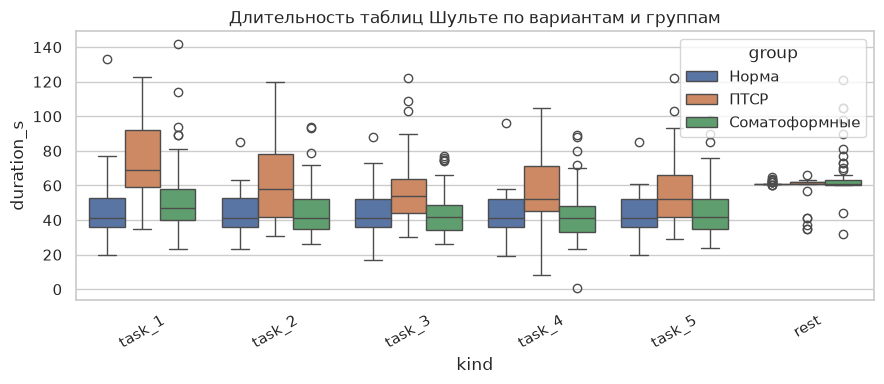

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=meta_df, x="kind", y="duration_s", hue="group", ax=ax)
ax.set_title("Длительность таблиц Шульте по вариантам и группам")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [13]:
pivot = (meta_df[meta_df["kind"].str.startswith("task_")]
         .pivot_table(index=["group", "subject"], columns="kind",
                      values="duration_s"))

# насколько различаются варианты внутри одного субъекта
print(pivot.describe().round(1))

# std по строке (внутрисубъектная вариативность по kind)
within_subj_std = pivot.std(axis=1)
print("\nВнутрисубъектный разброс duration по kind:")
print(within_subj_std.groupby(level="group").describe().round(1))

kind   task_1  task_2  task_3  task_4  task_5
count   165.0   165.0   165.0   165.0   165.0
mean     52.6    47.2    46.2    45.0    46.8
std      20.8    15.6    15.5    15.7    15.9
min      20.0    23.0    17.0     1.0    20.0
25%      40.0    36.0    36.0    36.0    36.0
50%      49.0    44.0    43.0    41.0    42.0
75%      58.0    53.0    53.0    52.0    53.0
max     142.0   120.0   122.0   105.0   122.0

Внутрисубъектный разброс duration по kind:
               count  mean  std  min  25%   50%   75%   max
group                                                      
Норма           67.0   2.7  4.7  0.0  0.0   0.0   4.0  20.4
ПТСР            25.0  13.3  7.4  3.8  7.8  12.2  18.8  31.9
Соматоформные   73.0  10.7  7.1  1.1  5.8   9.0  14.0  43.9


А вот утечка через duration — реальна и опаснее

Норма: mean 47, max 133

ПТСР: mean 61, max 123

Соматоформные: mean 49, max 142

Средние различаются (особенно ПТСР vs Норма), и min у Соматоформных = 1 с, чего нет у других. Модель, которая видит n_samples (или duration), получит частичный сигнал о группе — куда более устойчивый, чем через sfreq, потому что он отражает реальное поведение (ПТСР медленнее проходят таблицы) или реальные обрывы записи (1 с — точно артефакт).

Тут два варианта, и их надо различить:

(a) Физиология: ПТСР действительно дольше проходит таблицы Шульте (mean 61 vs 47). Тогда duration — валидный признак, не утечка.

(b) Артефакт: длительность зависит от пайплайна записи (кто-то записывал дольше), а не от задачи. Тогда — утечка.

T-П резко выделяется: длиннее всех (mean 62 vs 45–53), вдвое меньше разброс (std 9.4 vs 15–21), min = 32 с (нет мусора). Это не тот же тип задачи, что T-1…T-5, и модель это сразу заметит.

Нельзя смешивать T-П с T-1…T-5 в одной задаче.

У Нормы внутри одного субъекта таблицы проходятся за стабильное время (разброс по 6 вариантам ~8 с). У ПТСР и Соматоформных — почти вдвое больше разброс (~14–15 с).

Два объяснения:

(a) Физиология: у ПТСР/Соматоформных вариабельность прохождения — сама по себе симптом (тревожность, истощаемость, отвлекаемость). Это валидный сигнал, и его стоит использовать как фичу.

(b) Артефакт: у этих групп записи менее стабильны технически (обрывы, паузы), и разброс — следствие сбоев.


In [14]:
clean = meta_df[
    (meta_df["kind"].str.startswith("task_")) &
    (meta_df["duration_s"] >= 15)
].copy()
print("Было:", len(meta_df), "-> Осталось:", len(clean))
print(clean.groupby("group").size())

Было: 996 -> Осталось: 823
group
Норма            335
ПТСР             124
Соматоформные    364
dtype: int64


In [15]:
t_std  = clean[clean["kind"].isin([f"task_{i}" for i in range(1,6)])]
t_simp = clean[clean["kind"] == "task_simple"]

In [16]:
pivot_clean = t_std.pivot_table(index=["group","subject"], columns="kind",
                                values="duration_s")
within = pivot_clean.std(axis=1)
print(within.groupby(level="group").describe().round(1))

               count  mean  std  min  25%   50%   75%   max
group                                                      
Норма           67.0   2.7  4.7  0.0  0.0   0.0   4.0  20.4
ПТСР            25.0  12.8  6.5  3.8  7.8  12.2  18.3  25.0
Соматоформные   73.0  10.7  6.9  1.1  5.8   9.0  14.0  43.9


In [17]:
# посмотреть на длительности T-1..T-5 у нескольких Норма-субъектов
sample_norma = pivot_clean.loc["Норма"].head(10)
print(sample_norma.round(1))

# и у нескольких ПТСР
print(pivot_clean.loc["ПТСР"].head(10).round(1))

kind      task_1  task_2  task_3  task_4  task_5
subject                                         
КС010_19    63.0    44.0    50.0    33.0    50.0
КС011_25    60.0    54.0    60.0    52.0    37.0
КС012_58    35.0    58.0    51.0    58.0    51.0
КС013_23    44.0    33.0    27.0    29.0    26.0
КС014_22    43.0    39.0    39.0    49.0    43.0
КС015_35    54.0    37.0    47.0    39.0    39.0
КС016_22    67.0    50.0    73.0    53.0    61.0
КС017_51   133.0    85.0    88.0    96.0    85.0
КС022_22    71.0    49.0    52.0    39.0    47.0
КС023_20    52.0    63.0    39.0    35.0    43.0
kind     task_1  task_2  task_3  task_4  task_5
subject                                        
34PHG      66.0    58.0    50.0    53.0    66.0
BGVF       42.0    35.0    33.0    34.0    31.0
DFGH       36.0    31.0    30.0    25.0    29.0
ERTI       95.0    51.0    66.0     NaN    68.0
FGTG       79.0    49.0    57.0    74.0    53.0
GHJK       46.0    38.0    44.0    52.0    33.0
HJIK       92.0    75.0   12

In [18]:
norma = clean[(clean["group"] == "Норма") & (clean["kind"].str.match(r"task_[1-5]"))]
print(norma.groupby("subject")["duration_s"].agg(["count","min","max","nunique"]).head(15))

          count   min    max  nunique
subject                              
КС010_19      5  33.0   63.0        4
КС011_25      5  37.0   60.0        4
КС012_58      5  35.0   58.0        3
КС013_23      5  26.0   44.0        5
КС014_22      5  39.0   49.0        3
КС015_35      5  37.0   54.0        4
КС016_22      5  50.0   73.0        5
КС017_51      5  85.0  133.0        4
КС022_22      5  39.0   71.0        5
КС023_20      5  35.0   63.0        5
КС024_20      5  34.0   40.0        4
КС027_34      5  29.0   47.0        4
КС028_44      5  29.0   38.0        4
КС032_33      5  41.0   55.0        5
КС036_23      5  34.0   77.0        5


In [19]:
counts = pivot.notna().sum(axis=1)
print(counts.groupby(level="group").value_counts())

group           
Норма          5    67
ПТСР           5    25
Соматоформные  5    73
Name: count, dtype: int64


### Итоги, чтобы избежать утечки

1. ресемплируем к 125
2. Обрезать или исключить совсем короткие файлы
3. Не подавать в модель sfreq, n_samples, duration_s

### Визуализация сырых сигналов

Смотрим на форму сигнала и спектр по одному примеру из **каждой** группы —
и для покоя, и для таблицы Шульте, чтобы визуально прочувствовать разницу
в характере артефактов, которую описывает Приложение 1 (глазодвигательные
и двигательные артефакты в пробах, медленные артефакты под закрытыми
веками в покое).

In [20]:
def sample_subject_dir(group_name, seed=0):
    group_dir = DATA_DIR / group_name
    subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
    rng = random.Random(seed)
    return rng.choice(subj_dirs)
 
 
def plot_raw_snippet(path, ax, title, secs=10):
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    n = min(int(secs * fs), data.shape[1])
    for i, ch in enumerate(CHANNELS):
        ax.plot(np.arange(n) / fs, data[i, :n] - i * 200, label=ch, lw=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("с")

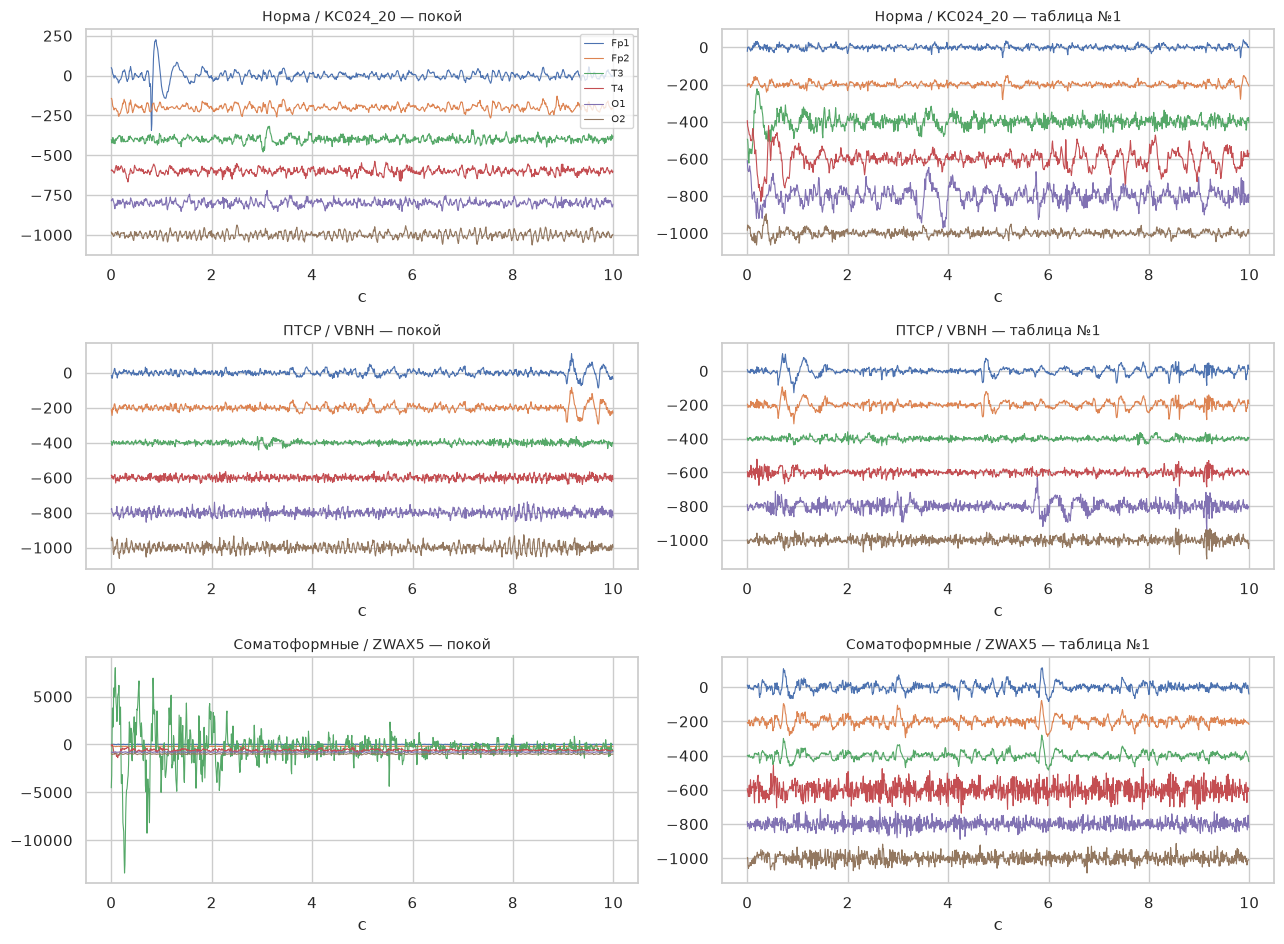

In [21]:
fig, axes = plt.subplots(len(GROUPS), 2, figsize=(13, 3.2 * len(GROUPS)))

for row, group_name in enumerate(GROUPS):
    subj_dir = sample_subject_dir(group_name, seed=row)
    files = sorted(subj_dir.glob("*.edf"))
    rest_f = next((f for f in files if classify_file(f.stem) == "rest"), None)
    task_f = next((f for f in files if classify_file(f.stem) == "task_1"), None)

    if rest_f:
        plot_raw_snippet(rest_f, axes[row, 0], f"{group_name} / {subj_dir.name} — покой")
    if task_f:
        plot_raw_snippet(task_f, axes[row, 1], f"{group_name} / {subj_dir.name} — таблица №1")

axes[0, 0].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

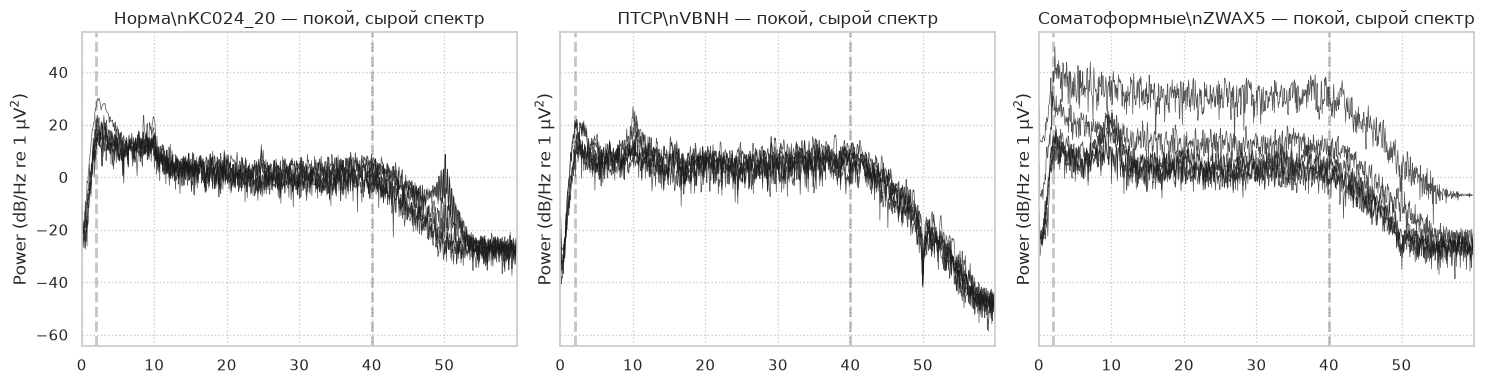

In [22]:
# то же самое, но в частотной области — сырой (нефильтрованный) спектр
fig, axes = plt.subplots(1, len(GROUPS), figsize=(15, 4), sharey=True)
 
for i, group_name in enumerate(GROUPS):
    subj_dir = sample_subject_dir(group_name, seed=i)
    rest_f = next((f for f in subj_dir.glob("*.edf") if classify_file(f.stem) == "rest"), None)
    if rest_f is None:
        continue
    raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
    raw.pick(CHANNELS)
    raw.compute_psd(fmax=60).plot(axes=axes[i], show=False)
    axes[i].set_title(f"{group_name}\\n{subj_dir.name} — покой, сырой спектр")
 
plt.tight_layout()
plt.show()

На сыром спектре пик 50 Гц (сетевая
наводка — должен уйти после notch-фильтра в препроцессинге),
выражен альфа-пик 8-13 Гц в покое (глаза закрыты), совсем плоских или "зашкаливающих" каналов не видно на этом этапе.

### Артефакты и выбросы: первичная (грубая) детекция

Без полноценного препроцессинга — просто чтобы понять масштаб проблемы:
сколько файлов имеют подозрительно плоские или подозрительно шумные
каналы. Именно эта диагностика в следующем ноутбуке ляжет в основу
`detect_bad_channels`.

In [23]:
def raw_channel_stats(path):
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    return {ch: dict(std=float(data[i].std()), ptp=float(np.ptp(data[i])))
            for i, ch in enumerate(CHANNELS)}

In [24]:
random.seed(1)
sample_files = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
    for subj_dir in random.sample(subj_dirs, min(20, len(subj_dirs))):
        for f in subj_dir.glob("*.edf"):
            sample_files.append((group_dir.name, subj_dir.name, f))
 
chstat_rows = []
for group, subj, f in sample_files:
    try:
        stats_ = raw_channel_stats(f)
        for ch, s in stats_.items():
            chstat_rows.append(dict(group=group, subject=subj, file=f.name,
                                     kind=classify_file(f.stem), channel=ch, **s))
    except Exception as e:
        chstat_rows.append(dict(group=group, subject=subj, file=f.name, error=str(e)))
 
chstat_df = pd.DataFrame(chstat_rows)


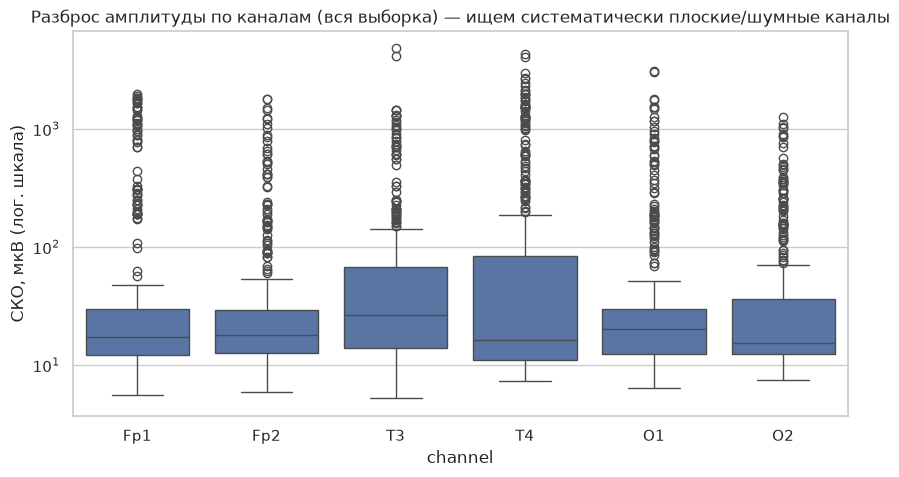

In [25]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=chstat_df, x="channel", y="std", order=CHANNELS)
plt.yscale("log")
plt.ylabel("СКО, мкВ (лог. шкала)")
plt.title("Разброс амплитуды по каналам (вся выборка) — ищем систематически плоские/шумные каналы")
plt.show()

In [26]:
# грубая эвристика для количественной оценки масштаба проблемы (финальные пороги — в след. ноутбуке)
flat_thresh_uv, noisy_ptp_uv = 0.5, 2000
 
flagged = chstat_df[(chstat_df["std"] < flat_thresh_uv) | (chstat_df["ptp"] > noisy_ptp_uv)]
print(f"Файлов×каналов с подозрением на артефакт: {len(flagged)} из {len(chstat_df)}")
print("\nПо каналам:")
print(flagged["channel"].value_counts())
print("\nПо группам:")
print(flagged["group"].value_counts())

Файлов×каналов с подозрением на артефакт: 425 из 2160

По каналам:
channel
T4     89
T3     77
O1     67
O2     65
Fp2    64
Fp1    63
Name: count, dtype: int64

По группам:
group
Соматоформные    257
ПТСР             159
Норма              9
Name: count, dtype: int64


T3 или T4 чаще всего страдают у
подобных гарнитур из-за посадки на височную область с волосами — это системная особенность гарнитуры/посадки.

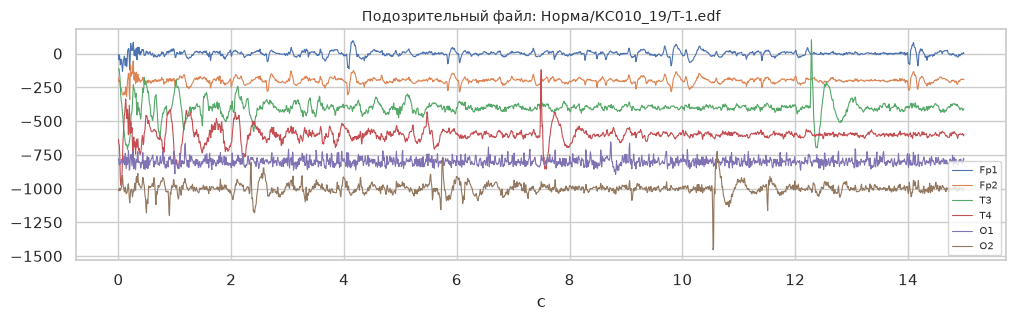

In [27]:
# пример одного явно "грязного" файла — посмотреть глазами, что там происходит
if len(flagged):
    example_bad = flagged.iloc[0]
    bad_path = DATA_DIR / example_bad["group"] / example_bad["subject"] / example_bad["file"]
    fig, ax = plt.subplots(figsize=(12, 3))
    plot_raw_snippet(bad_path, ax, f"Подозрительный файл: {example_bad['group']}/{example_bad['subject']}/{example_bad['file']}",
                      secs=15)
    ax.legend(fontsize=7)
    plt.show()

### Проверка систематической асимметрии из-за референса на левом ухе

**Ключевая проверка перед любыми выводами про межполушарную асимметрию.**
Референсный электрод — на левом ухе, значит левые каналы (Fp1, T3, O1)
физически ближе к референсу, чем правые (Fp2, T4, O2). Если это создаёт
систематическое смещение амплитуды, оно будет видно **на всей выборке
целиком, независимо от группы** — то есть это проверка не про ПТСР, а про
саму схему отведения.

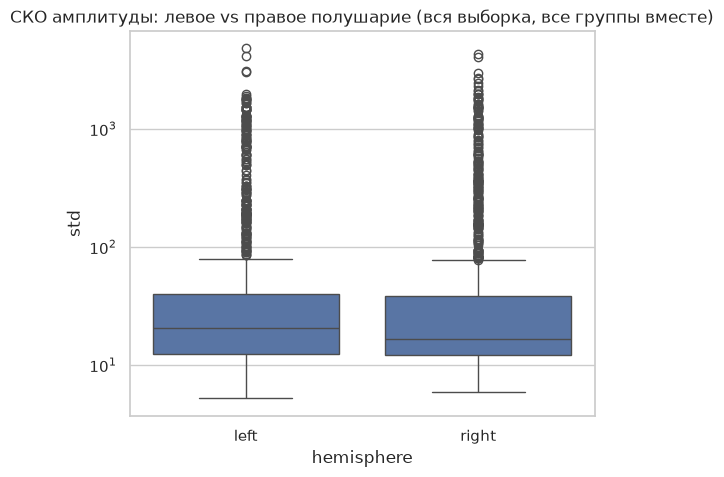

Mann-Whitney U, левые vs правые каналы (вся выборка): p=0.0028
Медиана СКО: левые=20.6 мкВ, правые=16.7 мкВ


In [28]:
hemis = chstat_df[chstat_df["channel"].isin(LEFT_CH + RIGHT_CH)].copy()
hemis["hemisphere"] = hemis["channel"].map(lambda c: "left" if c in LEFT_CH else "right")
 
plt.figure(figsize=(6, 5))
sns.boxplot(data=hemis, x="hemisphere", y="std")
plt.yscale("log")
plt.title("СКО амплитуды: левое vs правое полушарие (вся выборка, все группы вместе)")
plt.show()
 
left_std = hemis.loc[hemis["hemisphere"] == "left", "std"]
right_std = hemis.loc[hemis["hemisphere"] == "right", "std"]
w_stat, p_val = sps.mannwhitneyu(left_std, right_std)
print(f"Mann-Whitney U, левые vs правые каналы (вся выборка): p={p_val:.4f}")
print(f"Медиана СКО: левые={left_std.median():.1f} мкВ, правые={right_std.median():.1f} мкВ")

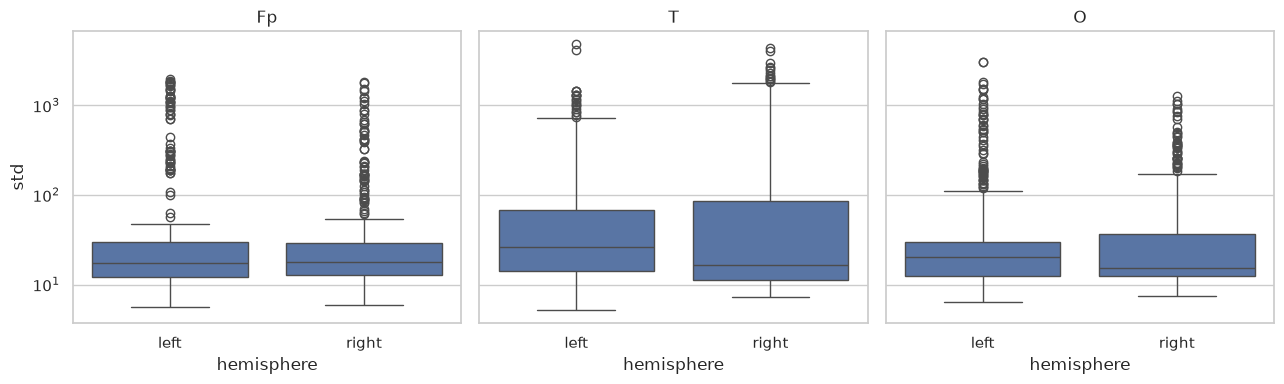

In [29]:
# то же самое попарно, по каждой из трёх осей Fp/T/O — вдруг эффект референса
# сильнее выражен на ближних к уху каналах (T), чем на дальних (Fp, O)
pair_names = {"Fp1": "Fp", "Fp2": "Fp", "T3": "T", "T4": "T", "O1": "O", "O2": "O"}
hemis["pair"] = hemis["channel"].map(pair_names)
 
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for i, pair in enumerate(["Fp", "T", "O"]):
    sub = hemis[hemis["pair"] == pair]
    sns.boxplot(data=sub, x="hemisphere", y="std", ax=axes[i])
    axes[i].set_yscale("log")
    axes[i].set_title(pair)
plt.tight_layout()
plt.show()

- Эффект сильнее всего на T (ближайшая к уху пара) и слабее на Fp/O —
 дело именно в удалённости от  референса, а не в реальной височной асимметрии. В предобработке  обязателен шаг **re-reference на средний по 6 каналам** перед вычислением  любых асимметрия-признаков и признаков связности — иначе  признаки будут частично или полностью кодировать не ПТСР, а геометрию электродов.
- Эта проверка не отменяет возможность реальной физиологической
  асимметрии при ПТСР

### Распределения по группам: грубые спектральные признаки

Без ICA/фильтрации артефактов — просто относительная мощность по
диапазонам на сыром сигнале (после базового bandpass 1-40 Гц, только чтобы
убрать дрейф и совсем высокочастотный шум), чтобы увидеть, есть ли вообще
визуально различимый сигнал между группами до какой-либо тонкой очистки.
Финальные признаки для модели считаются в следующем ноутбуке на полностью
очищенных данных — здесь только ориентировочная картина.

In [30]:
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}
 
 
def quick_rel_power(path):
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    raw.filter(1, 40, method="iir", verbose=False)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    f, p = signal.welch(data, fs=fs, nperseg=min(int(4 * fs), data.shape[1]), axis=-1)
    total = p[:, (f >= 1) & (f <= 40)].sum(axis=1, keepdims=True)
    return {band: (p[:, (f >= lo) & (f < hi)].sum(axis=1) / total[:, 0])
            for band, (lo, hi) in BANDS.items()}, f, p


In [31]:
random.seed(2)
eda_feat_rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
    for subj_dir in random.sample(subj_dirs, min(25, len(subj_dirs))):
        rest_f = next((f for f in subj_dir.glob("*.edf") if classify_file(f.stem) == "rest"), None)
        if rest_f is None:
            continue
        try:
            rp, _, _ = quick_rel_power(rest_f)
            row = dict(group=group_dir.name, subject=subj_dir.name,
                       age=get_age(group_dir.name, subj_dir.name))
            for band, vals in rp.items():
                for i, ch in enumerate(CHANNELS):
                    row[f"{ch}_{band}"] = float(vals[i])
            eda_feat_rows.append(row)
        except Exception:
            pass
 
eda_feat_df = pd.DataFrame(eda_feat_rows)
print(eda_feat_df.shape)


(75, 33)


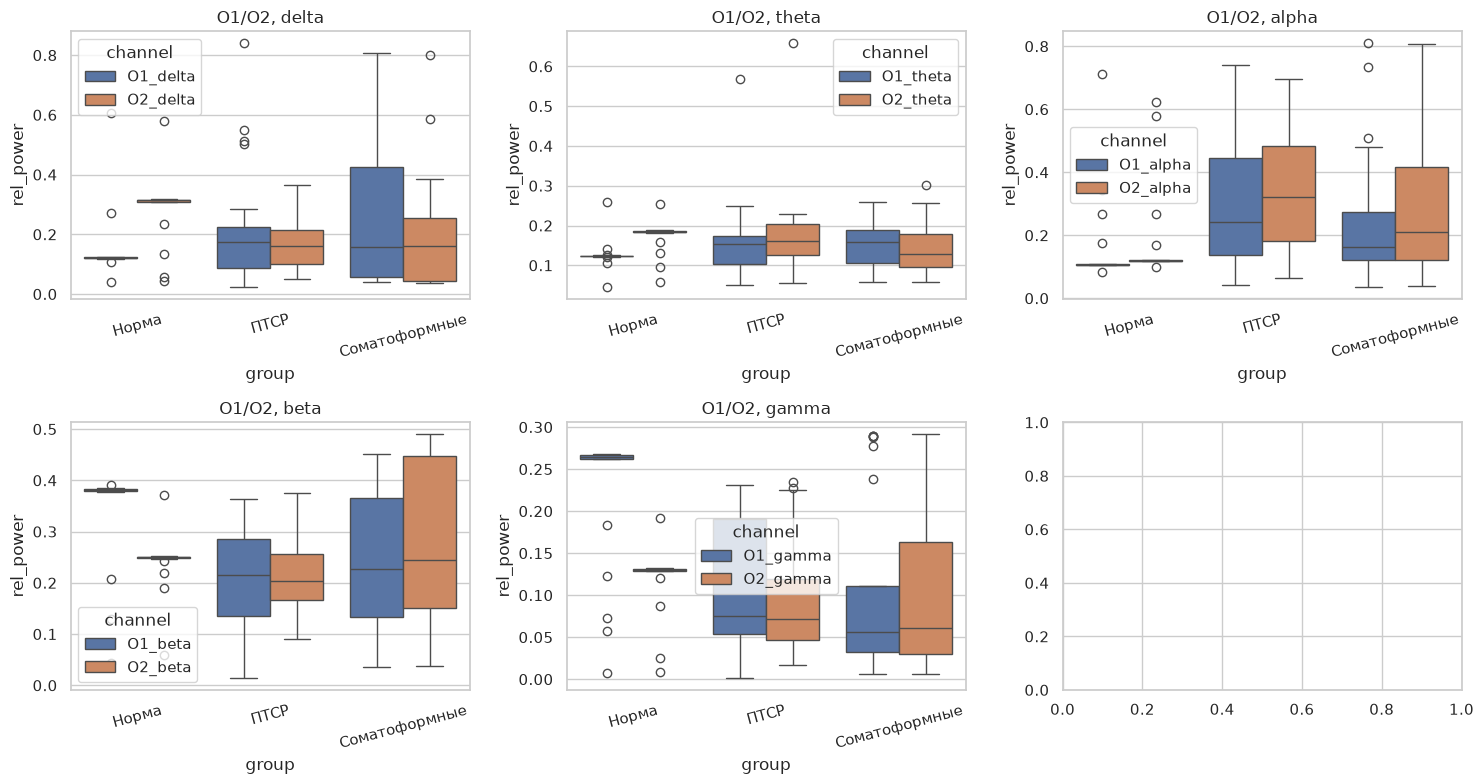

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, band in zip(axes.flat, BANDS):
    cols = [f"{ch}_{band}" for ch in ["O1", "O2"]]   # затылочные — самый чувствительный к состоянию покоя регион
    plot_df = eda_feat_df.melt(id_vars="group", value_vars=cols, var_name="channel", value_name="rel_power")
    sns.boxplot(data=plot_df, x="group", y="rel_power", hue="channel", order=GROUPS, ax=ax)
    ax.set_title(f"O1/O2, {band}")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [33]:
# то же в виде таблицы: медианы по группам, чтобы явно видеть направление разницы
summary_by_group = eda_feat_df.groupby("group")[[c for c in eda_feat_df.columns
                                                    if c not in ("group", "subject", "age")]].median()
summary_by_group.T.loc[[c for c in summary_by_group.columns if False] or
                         [f"{ch}_alpha" for ch in CHANNELS]]

group,Норма,ПТСР,Соматоформные
Fp1_alpha,0.119749,0.118264,0.120020
Fp2_alpha,0.129421,0.123808,0.119981
T3_alpha,0.250100,0.146048,0.149354
T4_alpha,0.125448,0.187428,0.175304
O1_alpha,0.106715,0.242321,0.162445
O2_alpha,0.119851,0.322495,0.209441


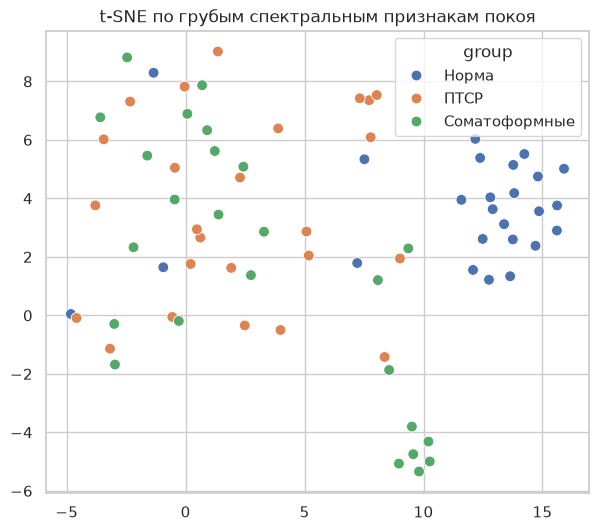

In [34]:
# t-SNE как чисто разведочная визуализация структуры (НЕ как доказательство разделимости — на LOO это не проверка)
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
 
feat_cols_quick = [c for c in eda_feat_df.columns if c not in ("group", "subject", "age")]
X_quick = SimpleImputer(strategy="median").fit_transform(eda_feat_df[feat_cols_quick])
X_quick = StandardScaler().fit_transform(X_quick)
 
emb = TSNE(n_components=2, perplexity=15, random_state=RANDOM_STATE, init="pca").fit_transform(X_quick)
 
plt.figure(figsize=(7, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=eda_feat_df["group"], hue_order=GROUPS, s=60)
plt.title("t-SNE по грубым спектральным признакам покоя")
plt.show()

t-SNE чисто разведочный инструмент — он не
валидируется через LOSO и легко "рисует" кажущиеся кластеры даже на шуме
при малой выборке.

### Доступные конфаундеры: возраст, пол, поведенческие показатели

Возраст известен только для группы 'Норма' (п. 3.1 ТЗ):
group
Норма            67
ПТСР              0
Соматоформные     0
Name: age, dtype: int64


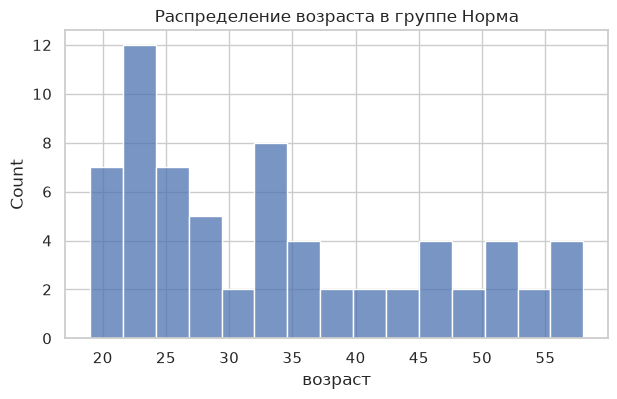

In [35]:
print("Возраст известен только для группы 'Норма' (п. 3.1 ТЗ):")
print(inv_df.groupby("group")["age"].apply(lambda s: s.notna().sum()))
 
plt.figure(figsize=(7, 4))
sns.histplot(inv_df.loc[inv_df["group"].str.lower().str.startswith("норм"), "age"], bins=15)
plt.title("Распределение возраста в группе Норма")
plt.xlabel("возраст")
plt.show()

**Пол.** В структуре данных (имена файлов/папок) пол испытуемого никак не
закодирован, доступна только сводка по группам в целом: 
контроль и ПТСР — мужчины, соматоформная группа смешанная по полу. Это
значит:
- пол **нельзя** использовать как признак или проверить как конфаундер
  на уровне отдельного испытуемого — только на уровне описания выборки
  в отчёте (группа ПТСР состоит из мужчин, это ограничение
  генерализуемости, а не то, что можно скорректировать в модели);
- при сравнении ПТСР vs Норма пол в целом сбалансирован по построению
  выборки (обе группы — мужчины), а вот соматоформная группа (проверка
  специфичности) смешанная

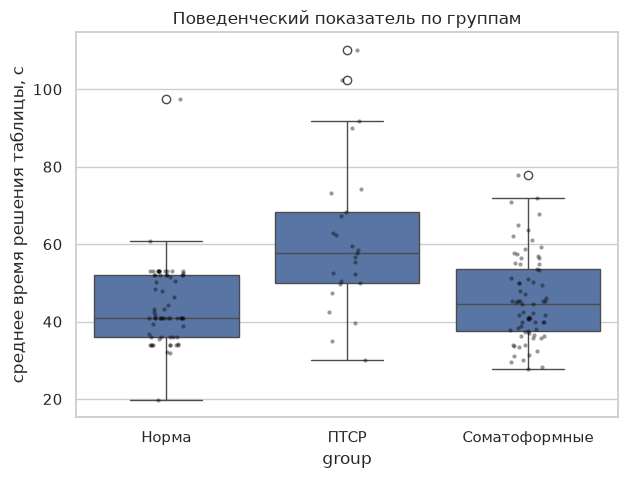

               count       mean        std   min   25%   50%   75%    max
group                                                                    
Норма           67.0  44.211940  10.388973  19.8  36.0  41.0  52.0   97.4
ПТСР            25.0  61.624000  19.916101  30.2  50.0  57.6  68.4  110.2
Соматоформные   73.0  45.791781  11.198335  27.8  37.6  44.6  53.6   77.8


In [36]:
# поведенческие показатели — длительность решения таблиц, по группам
task_meta = meta_df[meta_df["kind"].str.startswith("task")].copy()
subj_mean_dur = task_meta.groupby(["group", "subject"])["duration_s"].mean().reset_index()
 
plt.figure(figsize=(7, 5))
sns.boxplot(data=subj_mean_dur, x="group", y="duration_s", order=GROUPS)
sns.stripplot(data=subj_mean_dur, x="group", y="duration_s", order=GROUPS, color="black", alpha=0.4, size=3)
plt.ylabel("среднее время решения таблицы, с")
plt.title("Поведенческий показатель по группам")
plt.show()
 
print(subj_mean_dur.groupby("group")["duration_s"].describe())


Возраст vs время решения (Норма): r=0.259, p=0.034


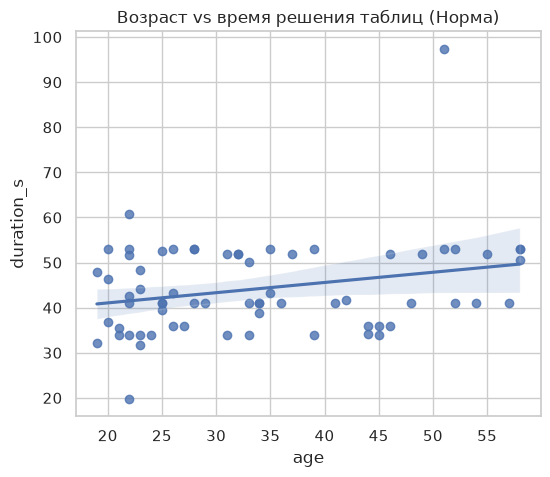

In [37]:
# возраст vs время решения внутри Нормы — если коррелирует, поведенческий признак
# частично конфаундирован возрастом, это нужно знать до моделирования
norm_beh = subj_mean_dur[subj_mean_dur["group"].str.lower().str.startswith("норм")].merge(
    inv_df[["group", "subject", "age"]], on=["group", "subject"]
)
r_age_beh, p_age_beh = sps.pearsonr(norm_beh["age"].dropna(),
                                     norm_beh.loc[norm_beh["age"].notna(), "duration_s"])
print(f"Возраст vs время решения (Норма): r={r_age_beh:.3f}, p={p_age_beh:.3f}")
 
plt.figure(figsize=(6, 5))
sns.regplot(data=norm_beh, x="age", y="duration_s")
plt.title("Возраст vs время решения таблиц (Норма)")
plt.show()

### Резюме

- нужно провести фильтрацию сырых ЭЭГ, убрать частоту 50 Гц, сделать re-reference и ресемплинг на частоту 125
- пол нельзя использовать как признак и отделить как конфаундер, группа гомогенная - мужчины
- распределение по возрасту известно для группы норма, далеко от нормального, превалирует группа до 30 лет
- есть некоторая корреляция между возрастом и длительностью решения таблиц

### Первичные гипотезы о признаках, связанных с ПТСР

1. **Межполушарная асимметрия Fp1/Fp2** — нужна поправка на
   инструментальный эффект референса.
2. **Поведенческие показатели** (время решения таблиц) — медленнее и/или
   более вариабельно при ПТСР.